# Análisis exploratorio y resultado de combinar las bases de datos 

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (11, 5)

raw_path = Path("../data/processed")

archivos = list(raw_path.glob("*.csv"))

len(archivos), archivos


(3,
 [WindowsPath('../data/processed/numero_estudiantes_intercambio_recibidos.csv'),
  WindowsPath('../data/processed/porcentaje_alumnos_hicieron_intercambio.csv'),
  WindowsPath('../data/processed/promedio_contribuciones_cien_tesis.csv')])

In [2]:

df_entrada = pd.read_csv(
    raw_path / "numero_estudiantes_intercambio_recibidos.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

df_salida = pd.read_csv(
    raw_path / "porcentaje_alumnos_hicieron_intercambio.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

df_investigacion = pd.read_csv(
    raw_path / "promedio_contribuciones_cien_tesis.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

for nombre, df in {
    "Movilidad entrante": df_entrada,
    "Movilidad saliente": df_salida,
    "Investigación": df_investigacion
}.items():
    print(f"\n{nombre}")
    print("Dimensiones:", df.shape)
    print("Columnas:", df.columns.tolist())
    print(df.dtypes)
    display(df.head())



Movilidad entrante
Dimensiones: (159, 9)
Columnas: ['COD_RUCT', 'TITULACION', 'CENTRO', '2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
COD_RUCT       object
TITULACION     object
CENTRO         object
2019-20       float64
2020-21       float64
2021-22       float64
2022-23       float64
2023-24       float64
2024-25       float64
dtype: object


,COD_RUCT,TITULACION,CENTRO,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,51.0,10.0,21.0,18.0,14.0,23.0
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,25.0,6.0,20.0,19.0,14.0,16.0
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,31.0,14.0,17.0,32.0,24.0,NaN
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,44.0,17.0,47.0,37.0,30.0,32.0
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,14.0,2.0,3.0,6.0,3.0,11.0



Movilidad saliente
Dimensiones: (141, 8)
Columnas: ['COD_RUCT', 'TITULACION', 'CENTRO', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
COD_RUCT       object
TITULACION     object
CENTRO         object
2020-21        object
2021-22       float64
2022-23       float64
2023-24       float64
2024-25       float64
dtype: object


,COD_RUCT,TITULACION,CENTRO,2020-21,2021-22,2022-23,2023-24,2024-25
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2.08,8.33,10.17,8.51,16.67
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,11.11,26.67,31.82,30.00,25.64
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,21.05,50.00,28.17,23.53,NaN
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,16.33,31.71,11.11,19.05,16.67
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,14.93,13.04,27.14,26.32,25.00



Investigación
Dimensiones: (32, 7)
Columnas: ['COD_RUCT', 'TITULACION', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
COD_RUCT       object
TITULACION     object
2020-21       float64
2021-22       float64
2022-23       float64
2023-24       float64
2024-25       float64
dtype: object


,COD_RUCT,TITULACION,2020-21,2021-22,2022-23,2023-24,2024-25
0,5600035,PROGRAMA DE DOCTORADO EN SISTEMAS PROPULSIVOS ...,6.22,6.00,5.32,5.00,5.53
1,5600036,PROGRAMA DE DOCTORADO EN CIENCIA Y TECNOLOGÍA ...,6.13,6.83,10.00,9.15,10.17
2,5600037,PROGRAMA DE DOCTORADO EN INFORMÁTICA,9.56,8.28,7.63,8.67,6.92
3,5600038,"PROGRAMA DE DOCTORADO EN ARQUITECTURA, EDIFICA...",11.88,8.50,8.67,7.86,8.37
4,5600039,PROGRAMA DE DOCTORADO EN ECONOMÍA AGROALIMENTARIA,4.00,3.50,5.00,8.57,8.17


# Datos ausentes y duplicados

Vemos que a lo largo de los años tenemos valores ausentes, pueden tratarse de grados nuevos que se han ido incorporando a la universidad.

In [3]:
for nombre, df in {
    "Entrada": df_entrada,
    "Salida": df_salida,
    "Investigación": df_investigacion
}.items():
    print(f"\n--- {nombre} ---")
    print("Filas duplicadas:", df.duplicated().sum())
    print("Valores ausentes:")
    display(df.isna().sum().to_frame("Nulos"))

    # Filas con al menos un nulo
    filas_nulas = df[df.isna().any(axis=1)]
    print(f"Filas con algún nulo: {len(filas_nulas)}")
    display(filas_nulas)


--- Entrada ---
Filas duplicadas: 0
Valores ausentes:


,Nulos
COD_RUCT,0
TITULACION,0
CENTRO,0
2019-20,46
2020-21,46
2021-22,40
2022-23,33
2023-24,30
2024-25,28


Filas con algún nulo: 73


,COD_RUCT,TITULACION,CENTRO,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,31.0,14.0,17.0,32.0,24.0,NaN
5,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,NaN,NaN,NaN,NaN,78.0,58.0
6,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E.T.S. DE INGENIERIA DEL DISEÑO,76.0,33.0,88.0,86.0,NaN,NaN
14,2501653,GRADO EN INGENIERÍA AEROESPACIAL,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,NaN,NaN,NaN,NaN,41.0,61.0
15,2501653,GRADO EN INGENIERÍA AEROESPACIAL,E.T.S. DE INGENIERIA DEL DISEÑO,37.0,12.0,39.0,52.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
154,4318256,MÁSTER UNIVERSITARIO EN SEGURIDAD INDUSTRIAL,E.T.S.I. INDUSTRIALES,NaN,NaN,NaN,NaN,0.0,0.0
155,4318298,MÁSTER UNIVERSITARIO EN INGENIERÍA EN MOVILIDA...,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,NaN,NaN,NaN,NaN,0.0,3.0
156,4318372,MÁSTER UNIVERSITARIO EN HUMANIDADES DIGITALES,E.T.S. DE INGENIERÍA INFORMÁTICA,NaN,NaN,NaN,NaN,0.0,0.0
157,4318375,MÁSTER UNIVERSITARIO EN INGENIERÍA ESTRUCTURAL...,"E.T.S.I. CAMINOS, CANALES Y PUERTOS",NaN,NaN,NaN,NaN,0.0,0.0



--- Salida ---
Filas duplicadas: 0
Valores ausentes:


,Nulos
COD_RUCT,0
TITULACION,0
CENTRO,0
2020-21,34
2021-22,29
2022-23,26
2023-24,24
2024-25,21


... (2 outputs left out)


--- Investigación ---
Filas duplicadas: 0
Valores ausentes:


,Nulos
COD_RUCT,0
TITULACION,0
2020-21,2
2021-22,3
2022-23,2
2023-24,1
2024-25,2


Filas con algún nulo: 3


,COD_RUCT,TITULACION,2020-21,2021-22,2022-23,2023-24,2024-25
23,5600356,PROGRAMA DE DOCTORADO EN TÉCNICAS EXPERIMENTAL...,4.0,NaN,6.5,10.5,NaN
30,5601427,"PROGRAMA DE DOCTORADO EN ARQUITECTURA, EDIFICA...",NaN,NaN,NaN,5.0,6.29
31,5601473,PROGRAMA DE DOCTORADO EN CIENCIA Y TECNOLOGÍA ...,NaN,NaN,NaN,NaN,NaN


In [4]:

def transformar_formato_largo(df, nombre_variable):
    df = df.copy()

    columnas_id = [
        col for col in ["COD_RUCT", "TITULACION", "CENTRO"]
        if col in df.columns
    ]

    columnas_curso = [
        col for col in df.columns
        if col not in columnas_id
    ]

    df_largo = df.melt(
        id_vars=columnas_id,
        value_vars=columnas_curso,
        var_name="CURSO",
        value_name=nombre_variable
    )

    # Conversión numérica, admitiendo coma decimal
    df_largo[nombre_variable] = pd.to_numeric(
        df_largo[nombre_variable]
          .astype("string")
          .str.replace(",", ".", regex=False),
        errors="coerce"
    )

    df_largo["COD_RUCT"] = (
        df_largo["COD_RUCT"].astype("string").str.strip()
    )

    if "CENTRO" in df_largo.columns:
        df_largo["CENTRO"] = (
            df_largo["CENTRO"].astype("string").str.strip()
        )

    df_largo["CURSO"] = df_largo["CURSO"].astype(str).str.strip()

    return df_largo


entrada = transformar_formato_largo(
    df_entrada, "MOVILIDAD_ENTRANTE"
)

salida = transformar_formato_largo(
    df_salida, "PORC_MOVILIDAD_SALIENTE"
)

investigacion = transformar_formato_largo(
    df_investigacion, "CONTRIBUCIONES_TESIS"
)

display(entrada.head())
display(salida.head())
display(investigacion.head())


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2019-20,51.0
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2019-20,25.0
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2019-20,31.0
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2019-20,44.0
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,2019-20,14.0


,COD_RUCT,TITULACION,CENTRO,CURSO,PORC_MOVILIDAD_SALIENTE
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,2.08
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,11.11
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,21.05
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,16.33
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21,14.93


,COD_RUCT,TITULACION,CURSO,CONTRIBUCIONES_TESIS
0,5600035,PROGRAMA DE DOCTORADO EN SISTEMAS PROPULSIVOS ...,2020-21,6.22
1,5600036,PROGRAMA DE DOCTORADO EN CIENCIA Y TECNOLOGÍA ...,2020-21,6.13
2,5600037,PROGRAMA DE DOCTORADO EN INFORMÁTICA,2020-21,9.56
3,5600038,"PROGRAMA DE DOCTORADO EN ARQUITECTURA, EDIFICA...",2020-21,11.88
4,5600039,PROGRAMA DE DOCTORADO EN ECONOMÍA AGROALIMENTARIA,2020-21,4.0


In [5]:
print(entrada.columns.tolist())

['COD_RUCT', 'TITULACION', 'CENTRO', 'CURSO', 'MOVILIDAD_ENTRANTE']


In [6]:

claves = ["COD_RUCT","TITULACION", "CENTRO", "CURSO"]

for nombre, df in {
    "Entrada": entrada,
    "Salida": salida
}.items():

    duplicados = df[
        df.duplicated(subset=claves, keep=False)
    ]

    print(f"{nombre}: {len(duplicados)} filas con clave repetida")

    if not duplicados.empty:
        display(duplicados.sort_values(claves).head(15))


Entrada: 0 filas con clave repetida
Salida: 0 filas con clave repetida


In [7]:

assert not entrada.duplicated(claves).any(), \
    "Hay claves duplicadas en movilidad entrante."

assert not salida.duplicated(claves).any(), \
    "Hay claves duplicadas en movilidad saliente."

# Evitamos duplicar la columna TITULACION
salida_merge = salida

df_movilidad = entrada.merge(
    salida_merge,
    on=claves,
    how="outer",
    validate="one_to_one",
    indicator=True
)

print("Resultado de la integración:")
display(df_movilidad.head())

print("\nProcedencia de los registros:")
display(df_movilidad["_merge"].value_counts())

df_movilidad = df_movilidad.drop(columns="_merge")

# Las dos fuentes coinciden entre 2020-21 y 2024-25
cursos_comunes = sorted(
    set(entrada["CURSO"]) & set(salida["CURSO"])
)

df_movilidad = df_movilidad[
    df_movilidad["CURSO"].isin(cursos_comunes)
].copy()

df_movilidad = df_movilidad.sort_values(
    ["CURSO", "COD_RUCT", "CENTRO"]
).reset_index(drop=True)

print("Dimensiones finales:", df_movilidad.shape)
display(df_movilidad.head())


Resultado de la integración:


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE,_merge
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2019-20,51.0,<NA>,left_only
1,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,10.0,2.08,both
2,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2021-22,21.0,8.33,both
3,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2022-23,18.0,10.17,both
4,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2023-24,14.0,8.51,both



Procedencia de los registros:


_merge
both          705
left_only     249
right_only      0
Name: count, dtype: int64

Dimensiones finales: (795, 6)


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,10.0,2.08
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,6.0,11.11
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,14.0,21.05
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,17.0,16.33
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21,2.0,14.93


In [8]:

print("Estadísticos descriptivos:")
display(
    df_movilidad[
        ["MOVILIDAD_ENTRANTE", "PORC_MOVILIDAD_SALIENTE"]
    ].describe()
)

print("\nValores ausentes:")
display(
    df_movilidad[
        ["MOVILIDAD_ENTRANTE", "PORC_MOVILIDAD_SALIENTE"]
    ].isna().sum()
)

print("\nRegistros con valores sospechosos:")

sospechosos = df_movilidad[
    (df_movilidad["MOVILIDAD_ENTRANTE"] < 0)
    | (df_movilidad["PORC_MOVILIDAD_SALIENTE"] < 0)
    | (df_movilidad["PORC_MOVILIDAD_SALIENTE"] > 100)
]

display(sospechosos)


Estadísticos descriptivos:


,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE
count,618.0,571.0
mean,13.634304,11.56725
std,29.280163,13.136651
min,0.0,0.0
25%,0.0,0.0
50%,2.0,7.02
75%,12.0,18.96
max,229.0,75.0



Valores ausentes:


MOVILIDAD_ENTRANTE         177
PORC_MOVILIDAD_SALIENTE    224
dtype: int64


Registros con valores sospechosos:


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE


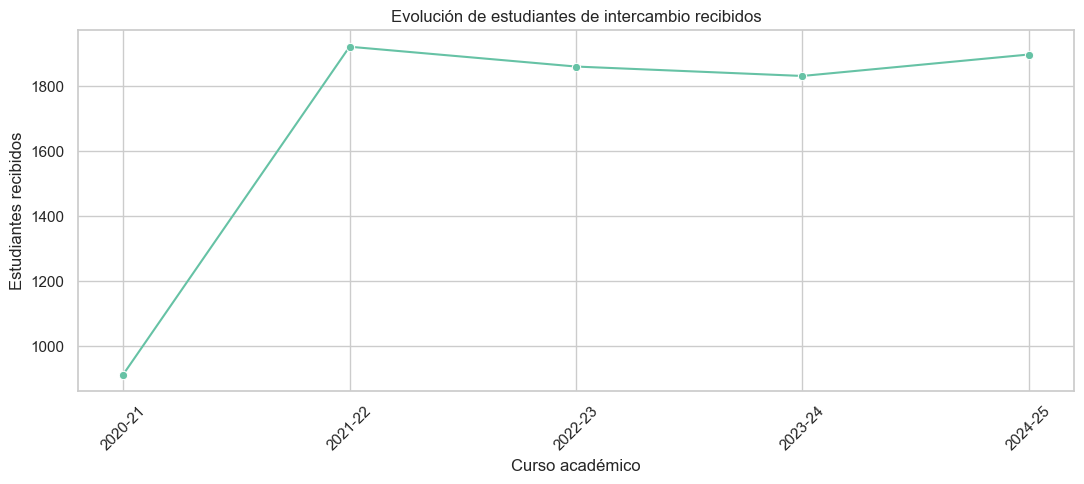

,CURSO,MOVILIDAD_ENTRANTE
0,2020-21,913.0
1,2021-22,1922.0
2,2022-23,1861.0
3,2023-24,1832.0
4,2024-25,1898.0


In [9]:

movilidad_anual = (
    df_movilidad.groupby("CURSO")["MOVILIDAD_ENTRANTE"]
    .sum(min_count=1)
    .reset_index()
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=movilidad_anual,
    x="CURSO",
    y="MOVILIDAD_ENTRANTE",
    marker="o"
)

plt.title("Evolución de estudiantes de intercambio recibidos")
plt.xlabel("Curso académico")
plt.ylabel("Estudiantes recibidos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(movilidad_anual)


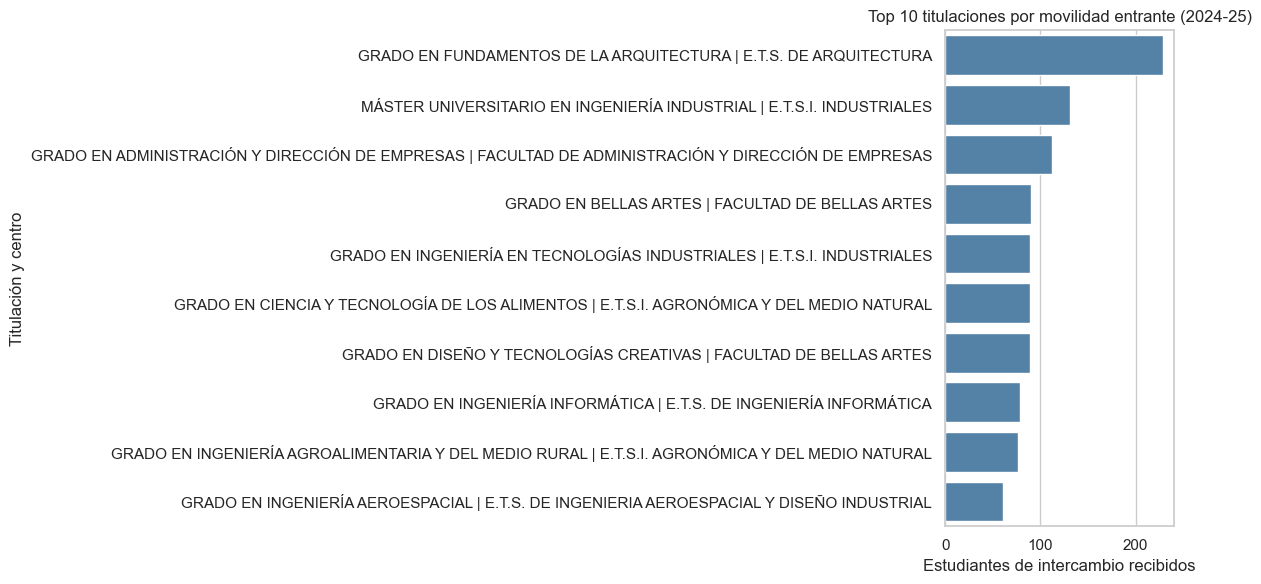

In [10]:

curso_seleccionado = "2024-25"

top_entrada = (
    df_movilidad[
        df_movilidad["CURSO"] == curso_seleccionado
    ]
    .dropna(subset=["MOVILIDAD_ENTRANTE"])
    .sort_values("MOVILIDAD_ENTRANTE", ascending=False)
    .head(10)
    .copy()
)

top_entrada["TITULACION_CENTRO"] = (
    top_entrada["TITULACION"] + " | "
    + top_entrada["CENTRO"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_entrada,
    x="MOVILIDAD_ENTRANTE",
    y="TITULACION_CENTRO",
    color="steelblue"
)

plt.title(f"Top 10 titulaciones por movilidad entrante ({curso_seleccionado})")
plt.xlabel("Estudiantes de intercambio recibidos")
plt.ylabel("Titulación y centro")
plt.tight_layout()
plt.show()


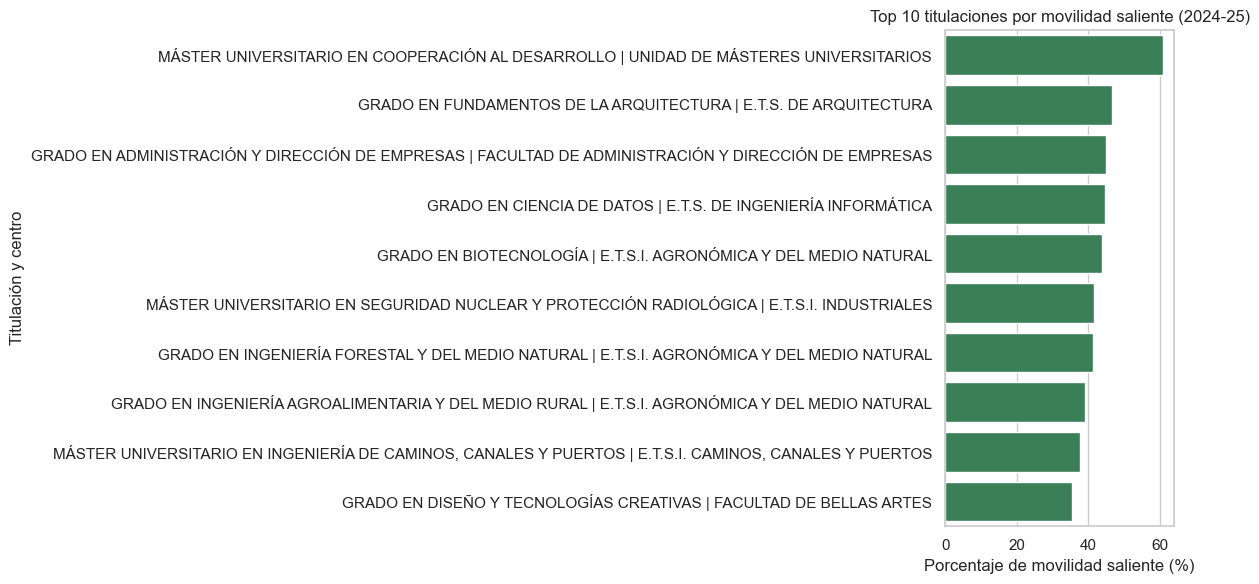

In [11]:

top_salida = (
    df_movilidad[
        df_movilidad["CURSO"] == curso_seleccionado
    ]
    .dropna(subset=["PORC_MOVILIDAD_SALIENTE"])
    .sort_values("PORC_MOVILIDAD_SALIENTE", ascending=False)
    .head(10)
    .copy()
)

top_salida["TITULACION_CENTRO"] = (
    top_salida["TITULACION"] + " | "
    + top_salida["CENTRO"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_salida,
    x="PORC_MOVILIDAD_SALIENTE",
    y="TITULACION_CENTRO",
    color="seagreen"
)

plt.title(f"Top 10 titulaciones por movilidad saliente ({curso_seleccionado})")
plt.xlabel("Porcentaje de movilidad saliente (%)")
plt.ylabel("Titulación y centro")
plt.tight_layout()
plt.show()


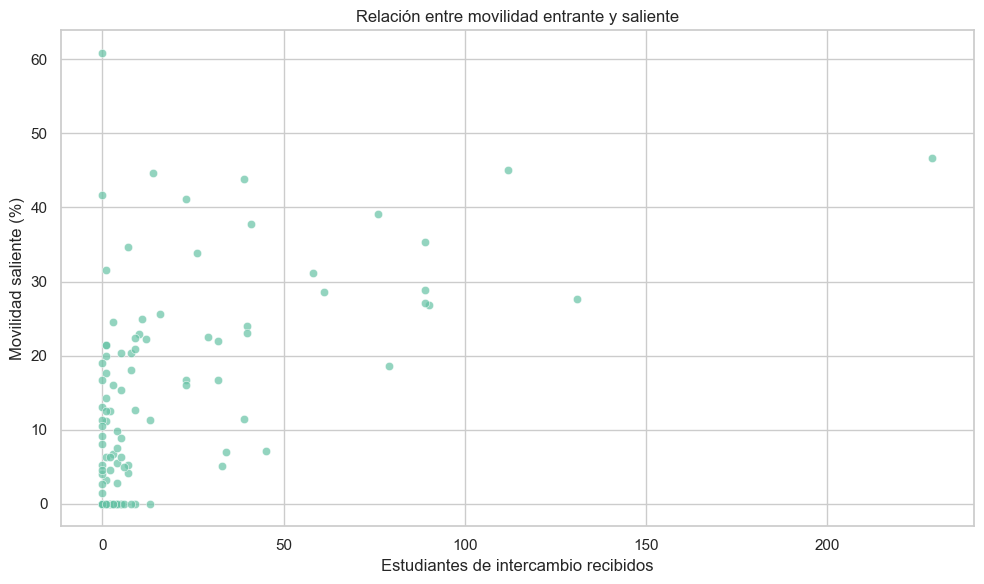

,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE
MOVILIDAD_ENTRANTE,1.000000,0.598894
PORC_MOVILIDAD_SALIENTE,0.598894,1.000000


In [12]:

df_relacion = df_movilidad[
    df_movilidad["CURSO"] == curso_seleccionado
].dropna(
    subset=["MOVILIDAD_ENTRANTE", "PORC_MOVILIDAD_SALIENTE"]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_relacion,
    x="MOVILIDAD_ENTRANTE",
    y="PORC_MOVILIDAD_SALIENTE",
    alpha=0.7
)

plt.title("Relación entre movilidad entrante y saliente")
plt.xlabel("Estudiantes de intercambio recibidos")
plt.ylabel("Movilidad saliente (%)")
plt.tight_layout()
plt.show()

correlacion = df_relacion[
    ["MOVILIDAD_ENTRANTE", "PORC_MOVILIDAD_SALIENTE"]
].corr(method="spearman")

display(correlacion)


In [13]:

path_matricula = Path("../datos/Alumnos_matriculados_2020_2024.csv")

df_matricula = pd.read_csv(
    path_matricula,
    sep=";",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

display(df_matricula.head())
print(df_matricula.shape)


,CURSO,COD_RUCT,TITULACION,CENTRO,NUMERO_ALUMNOS_MATRICULADOS
0,2020-21,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,450
1,2020-21,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,224
2,2020-21,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,376
3,2020-21,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,378
4,2020-21,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,356


(615, 5)


In [14]:

df_matricula["CENTRO"] = (
    df_matricula["CENTRO"].astype("string").str.strip()
)

df_matricula["CURSO"] = (
    df_matricula["CURSO"].astype(str).str.strip()
)

df_matricula["COD_RUCT"] = (
    df_matricula["COD_RUCT"].astype("string").str.strip()
)

print("Claves duplicadas en matrícula:")
display(
    df_matricula[
        df_matricula.duplicated(claves, keep=False)
    ]
)

assert not df_matricula.duplicated(claves).any(), \
    "Revisa las claves duplicadas en matrícula."

df_final = df_movilidad.merge(
    df_matricula[
        claves + ["NUMERO_ALUMNOS_MATRICULADOS"]
    ],
    on=claves,
    how="left",
    validate="one_to_one"
)

print("Registros sin matrícula:")
print(df_final["NUMERO_ALUMNOS_MATRICULADOS"].isna().sum())

display(df_final.head())


Claves duplicadas en matrícula:


,CURSO,COD_RUCT,TITULACION,CENTRO,NUMERO_ALUMNOS_MATRICULADOS


Registros sin matrícula:
180


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE,NUMERO_ALUMNOS_MATRICULADOS
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,10.0,2.08,450.0
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,6.0,11.11,224.0
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,14.0,21.05,376.0
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,17.0,16.33,378.0
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21,2.0,14.93,356.0


In [34]:

# Conservamos todas las observaciones
df_final = df_final.copy()

# Calculamos únicamente cuando tenemos ambas variables
df_final["RATIO_MOVILIDAD_ENTRANTE"] = np.where(
    df_final["MOVILIDAD_ENTRANTE"].notna()
    & df_final["NUMERO_ALUMNOS_MATRICULADOS"].notna()
    & (df_final["NUMERO_ALUMNOS_MATRICULADOS"] > 0),

    df_final["MOVILIDAD_ENTRANTE"]
    / df_final["NUMERO_ALUMNOS_MATRICULADOS"] * 100,

    np.nan
)

print("Registros totales:", len(df_final))

print(
    "Registros con ratio válida:",
    df_final["RATIO_MOVILIDAD_ENTRANTE"].notna().sum()
)

display(df_final.head())


Registros totales: 795
Registros con ratio válida: 615


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE,NUMERO_ALUMNOS_MATRICULADOS,RATIO_MOVILIDAD_ENTRANTE
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,10.0,2.08,450.0,2.222222
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,6.0,11.11,224.0,2.678571
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,14.0,21.05,376.0,3.723404
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,17.0,16.33,378.0,4.497354
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DESARROLLO DE PRODUCTOS,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21,2.0,14.93,356.0,0.561798


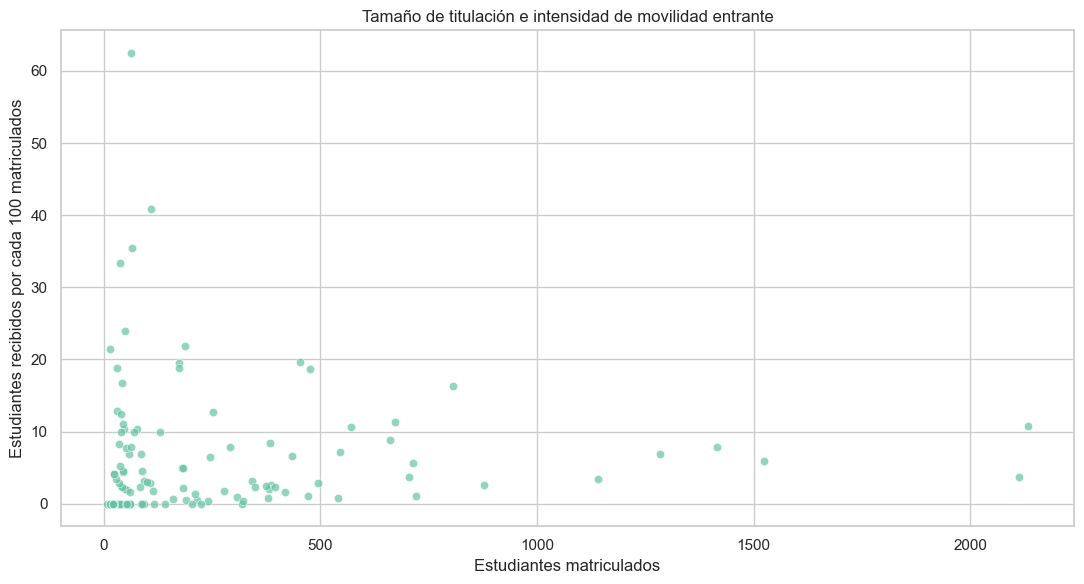

Observaciones utilizadas: 130


In [35]:


df_grafico = df_final[
    (df_final["CURSO"] == curso_seleccionado)
    & df_final["RATIO_MOVILIDAD_ENTRANTE"].notna()
    & df_final["NUMERO_ALUMNOS_MATRICULADOS"].notna()
].copy()

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_grafico,
    x="NUMERO_ALUMNOS_MATRICULADOS",
    y="RATIO_MOVILIDAD_ENTRANTE",
    alpha=0.7
)

plt.title("Tamaño de titulación e intensidad de movilidad entrante")
plt.xlabel("Estudiantes matriculados")
plt.ylabel("Estudiantes recibidos por cada 100 matriculados")
plt.tight_layout()
plt.show()

print("Observaciones utilizadas:", len(df_grafico))


,CENTRO,estudiantes,movilidad_entrante,titulaciones,RATIO_MOVILIDAD
5,E.T.S.I. AGRONÓMICA Y DEL MEDIO NATURAL,2347.0,272.0,10,11.589263
12,FACULTAD DE BELLAS ARTES,2547.0,193.0,4,7.577542
1,E.T.S. DE ARQUITECTURA,3536.0,260.0,5,7.352941
8,"E.T.S.I. GEODESICA, CARTOGRAFICA Y TOP.",374.0,26.0,2,6.951872
2,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,3620.0,247.0,12,6.823204
9,E.T.S.I. INDUSTRIALES,4133.0,279.0,14,6.750544
6,"E.T.S.I. CAMINOS, CANALES Y PUERTOS",1011.0,63.0,8,6.231454
11,FACULTAD DE ADMINISTRACIÓN Y DIRECCIÓN DE EMPRESAS,1918.0,113.0,6,5.891554
10,ESCUELA POLITECNICA SUPERIOR DE GANDIA,1289.0,70.0,12,5.430566
4,E.T.S. DE INGENIERÍA INFORMÁTICA,2968.0,140.0,6,4.716981


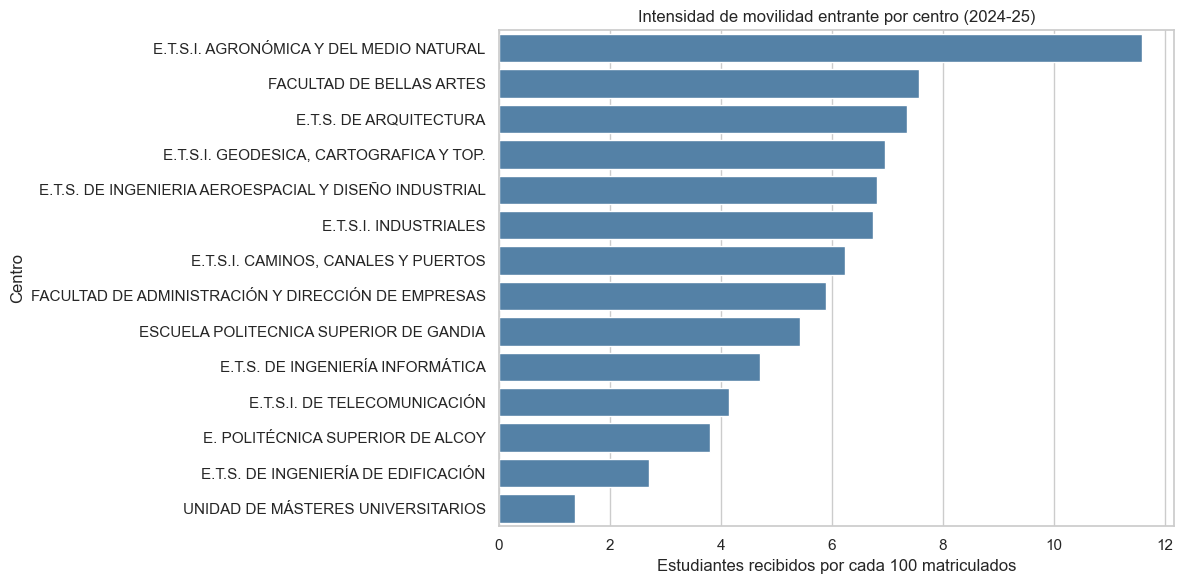

In [36]:

df_centros_validos = df_final[
    (df_final["CURSO"] == curso_seleccionado)
    & df_final["RATIO_MOVILIDAD_ENTRANTE"].notna()
].copy()

centros = (
    df_centros_validos
    .groupby("CENTRO", as_index=False)
    .agg(
        estudiantes=("NUMERO_ALUMNOS_MATRICULADOS", "sum"),
        movilidad_entrante=("MOVILIDAD_ENTRANTE", "sum"),
        titulaciones=("COD_RUCT", "nunique")
    )
)

centros["RATIO_MOVILIDAD"] = (
    centros["movilidad_entrante"]
    / centros["estudiantes"] * 100
)

centros = centros.sort_values(
    "RATIO_MOVILIDAD",
    ascending=False
)

display(centros)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=centros,
    x="RATIO_MOVILIDAD",
    y="CENTRO",
    color="steelblue"
)

plt.title(f"Intensidad de movilidad entrante por centro ({curso_seleccionado})")
plt.xlabel("Estudiantes recibidos por cada 100 matriculados")
plt.ylabel("Centro")
plt.tight_layout()
plt.show()


Estadísticos de investigación:


count       150.0
mean     7.783933
std      2.560766
min          2.45
25%           6.0
50%         7.665
75%         9.075
max         16.41
Name: CONTRIBUCIONES_TESIS, dtype: Float64


Valores ausentes:


COD_RUCT                 0
TITULACION               0
CURSO                    0
CONTRIBUCIONES_TESIS    10
dtype: int64

,CURSO,mean,median,count
0,2020-21,8.062333,8.18,30
1,2021-22,7.602069,7.33,29
2,2022-23,8.264667,8.625,30
3,2023-24,7.250968,7.43,31
4,2024-25,7.751333,7.345,30


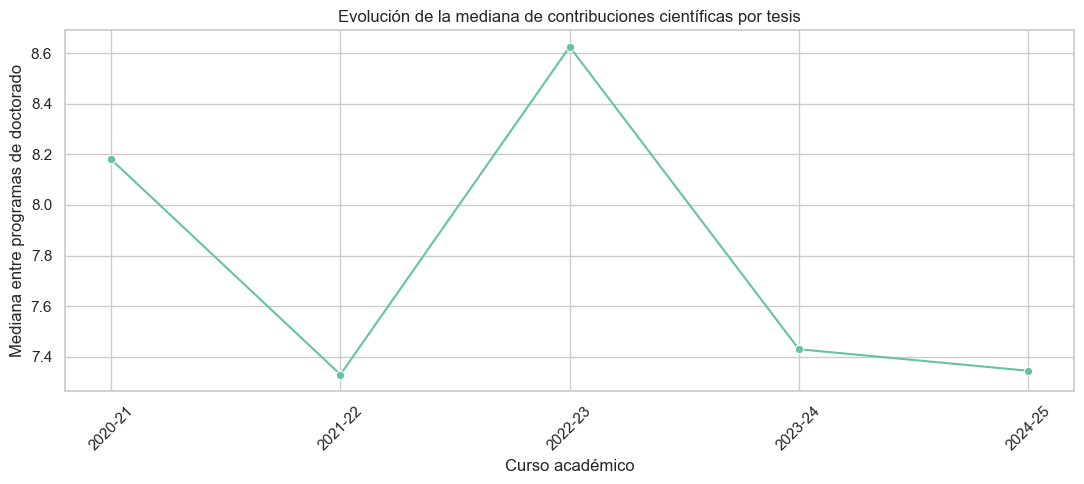

In [18]:

print("Estadísticos de investigación:")
display(investigacion["CONTRIBUCIONES_TESIS"].describe())

print("\nValores ausentes:")
display(investigacion.isna().sum())

# Evolución del promedio de contribuciones por programa
evolucion_investigacion = (
    investigacion.groupby("CURSO")["CONTRIBUCIONES_TESIS"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

display(evolucion_investigacion)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=evolucion_investigacion,
    x="CURSO",
    y="median",
    marker="o"
)

plt.title("Evolución de la mediana de contribuciones científicas por tesis")
plt.xlabel("Curso académico")
plt.ylabel("Mediana entre programas de doctorado")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


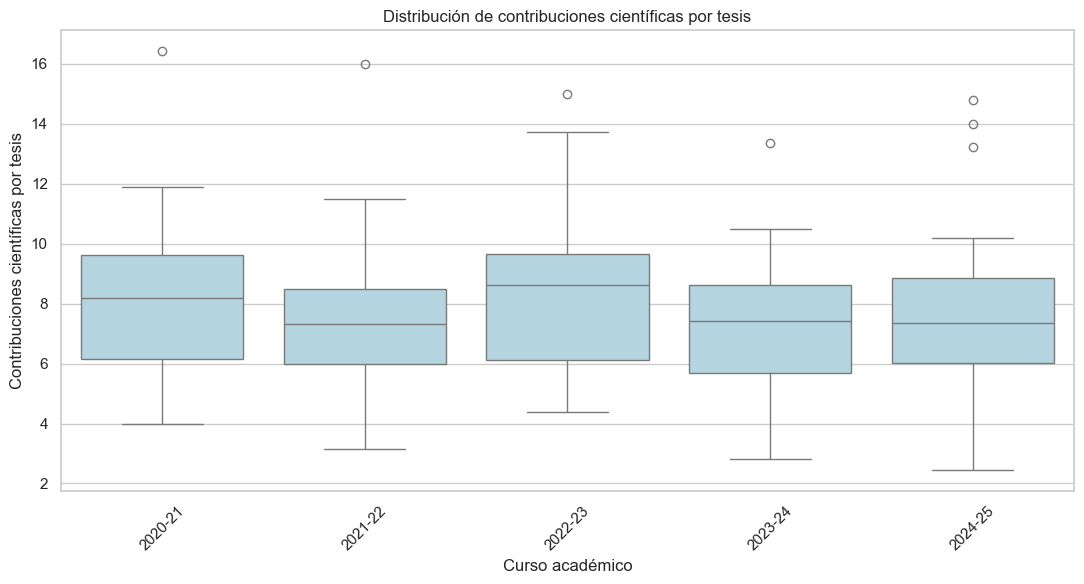

In [19]:

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=investigacion,
    x="CURSO",
    y="CONTRIBUCIONES_TESIS",
    color="lightblue"
)

plt.title("Distribución de contribuciones científicas por tesis")
plt.xlabel("Curso académico")
plt.ylabel("Contribuciones científicas por tesis")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [20]:

claves = ["COD_RUCT", "TITULACION", "CENTRO", "CURSO"]

# Comprobar unicidad de las claves
print("Duplicados en movilidad:", df_movilidad.duplicated(claves).sum())
print("Duplicados en matrícula:", df_matricula.duplicated(claves).sum())

# Crear tabla auxiliar con las claves de matrícula
claves_matricula = df_matricula[claves].drop_duplicates()

# Diagnosticar correspondencias
diagnostico = df_movilidad.merge(
    claves_matricula,
    on=claves,
    how="left",
    validate="one_to_one",
    indicator=True
)

sin_matricula = diagnostico[
    diagnostico["_merge"] == "left_only"
].copy()

print("Registros sin correspondencia:", len(sin_matricula))

display(
    sin_matricula[
        ["COD_RUCT", "TITULACION", "CENTRO", "CURSO"]
    ]
)


Duplicados en movilidad: 0
Duplicados en matrícula: 0
Registros sin correspondencia: 180


,COD_RUCT,TITULACION,CENTRO,CURSO
5,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,2020-21
14,2501653,GRADO EN INGENIERÍA AEROESPACIAL,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,2020-21
18,2501655,GRADO EN INGENIERÍA ELÉCTRICA,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,2020-21
20,2501656,GRADO EN INGENIERÍA ELECTRÓNICA INDUSTRIAL Y A...,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,2020-21
32,2502182,GRADO EN INGENIERÍA MECÁNICA,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,2020-21
...,...,...,...,...
769,4315739,MÁSTER UNIVERSITARIO EN ARQUITECTURA DEL PAISAJE,E.T.S. DE ARQUITECTURA,2024-25
771,4315941,MÁSTER UNIVERSITARIO ERASMUS MUNDUS EN SANIDAD...,UNIDAD DE MÁSTERES UNIVERSITARIOS,2024-25
775,4316846,MÁSTER UNIVERSITARIO ERASMUS MUNDUS EN MEJORA ...,UNIDAD DE MÁSTERES UNIVERSITARIOS,2024-25
785,4317946,MÁSTER UNIVERSITARIO EN INCENDIOS FORESTALES. ...,E.T.S.I. AGRONÓMICA Y DEL MEDIO NATURAL,2024-25


In [29]:
pd.set_option("display.max_colwidth", None)
comparacion = sin_matricula.merge(
    df_matricula[
        ["TITULACION", "CURSO", "CENTRO"]
    ].rename(columns={
        "CENTRO": "CENTRO_MATRICULA"
    }),
    on=["TITULACION", "CURSO"],
    how="left"
)

# Mostrar los casos donde existe la titulación
# en matrícula, pero no coincide el centro
diferencias_centro = comparacion[
    comparacion["CENTRO_MATRICULA"].notna()
].copy()

display(
    diferencias_centro[
        [
            "COD_RUCT",
            "TITULACION",
            "CURSO",
            "CENTRO",
            "CENTRO_MATRICULA"
        ]
    ]
)


,COD_RUCT,TITULACION,CURSO,CENTRO,CENTRO_MATRICULA
0,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DESARROLLO DE PRODUCTOS,2020-21,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,E. POLITÉCNICA SUPERIOR DE ALCOY
1,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DESARROLLO DE PRODUCTOS,2020-21,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,E.T.S. DE INGENIERIA DEL DISEÑO
2,2501653,GRADO EN INGENIERÍA AEROESPACIAL,2020-21,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,E.T.S. DE INGENIERIA DEL DISEÑO
3,2501655,GRADO EN INGENIERÍA ELÉCTRICA,2020-21,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,E. POLITÉCNICA SUPERIOR DE ALCOY
4,2501655,GRADO EN INGENIERÍA ELÉCTRICA,2020-21,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,E.T.S. DE INGENIERIA DEL DISEÑO
...,...,...,...,...,...
183,4310975,MÁSTER UNIVERSITARIO EN INGENIERÍA DEL MANTENIMIENTO,2024-25,E.T.S. DE INGENIERIA DEL DISEÑO,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL
185,4311605,MÁSTER UNIVERSITARIO EN GESTIÓN DE LA SEGURIDAD Y CALIDAD ALIMENTARIA,2024-25,E.T.S.I. AGRONÓMICA Y DEL MEDIO NATURAL,UNIDAD DE MÁSTERES UNIVERSITARIOS
188,4314067,MÁSTER UNIVERSITARIO EN INGENIERÍA MECATRÓNICA,2024-25,E.T.S. DE INGENIERIA DEL DISEÑO,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL
189,4314521,MÁSTER UNIVERSITARIO EN INGENIERÍA AERONÁUTICA,2024-25,E.T.S. DE INGENIERIA DEL DISEÑO,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL


In [30]:

claves = ["COD_RUCT", "TITULACION", "CENTRO", "CURSO"]

diagnostico = df_movilidad.merge(
    df_matricula[
        claves + ["NUMERO_ALUMNOS_MATRICULADOS"]
    ],
    on=claves,
    how="left",
    indicator=True,
    validate="one_to_one"
)

sin_correspondencia = diagnostico[
    diagnostico["_merge"] == "left_only"
].copy()

print("Registros sin correspondencia:", len(sin_correspondencia))


Registros sin correspondencia: 180


In [32]:

primer_curso = (
    df_matricula
    .groupby(
        ["COD_RUCT", "TITULACION", "CENTRO"],
        as_index=False
    )
    .agg(PRIMER_CURSO=("CURSO", "min"))
)

display(primer_curso.head(20))


,COD_RUCT,TITULACION,CENTRO,PRIMER_CURSO
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DESARROLLO DE PRODUCTOS,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21
5,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DESARROLLO DE PRODUCTOS,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,2023-24
6,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DESARROLLO DE PRODUCTOS,E.T.S. DE INGENIERIA DEL DISEÑO,2020-21
7,2501484,GRADO EN BELLAS ARTES,FACULTAD DE BELLAS ARTES,2020-21
8,2501485,GRADO EN CONSERVACIÓN Y RESTAURACIÓN DE BIENES CULTURALES,FACULTAD DE BELLAS ARTES,2020-21
9,2501486,GRADO EN GESTIÓN Y ADMINISTRACIÓN PÚBLICA,FACULTAD DE ADMINISTRACIÓN Y DIRECCIÓN DE EMPRESAS,2020-21


In [33]:

df_diagnostico = df_final.copy()

df_diagnostico = df_diagnostico.merge(
    primer_curso,
    on=["COD_RUCT", "TITULACION", "CENTRO"],
    how="left",
    validate="many_to_one"
)

def clasificar_registro(fila):

    if pd.notna(fila["NUMERO_ALUMNOS_MATRICULADOS"]):
        return "Con matrícula"

    if pd.isna(fila["PRIMER_CURSO"]):
        return "Sin titulación-centro en matrícula"

    if fila["CURSO"] < fila["PRIMER_CURSO"]:
        return "Anterior al primer curso registrado"

    return "Sin matrícula en un curso posterior"


df_diagnostico["ESTADO_MATRICULA"] = (
    df_diagnostico.apply(clasificar_registro, axis=1)
)

display(
    df_diagnostico["ESTADO_MATRICULA"]
    .value_counts()
)

display(
    df_diagnostico[
        df_diagnostico["NUMERO_ALUMNOS_MATRICULADOS"].isna()
    ][
        [
            "TITULACION",
            "CENTRO",
            "CURSO",
            "PRIMER_CURSO",
            "ESTADO_MATRICULA"
        ]
    ].head(30)
)


ESTADO_MATRICULA
Con matrícula                          615
Anterior al primer curso registrado    103
Sin titulación-centro en matrícula      40
Sin matrícula en un curso posterior     37
Name: count, dtype: int64

,TITULACION,CENTRO,CURSO,PRIMER_CURSO,ESTADO_MATRICULA
5,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DESARROLLO DE PRODUCTOS,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,2020-21,2023-24,Anterior al primer curso registrado
14,GRADO EN INGENIERÍA AEROESPACIAL,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,2020-21,2023-24,Anterior al primer curso registrado
18,GRADO EN INGENIERÍA ELÉCTRICA,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,2020-21,2023-24,Anterior al primer curso registrado
20,GRADO EN INGENIERÍA ELECTRÓNICA INDUSTRIAL Y AUTOMÁTICA,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,2020-21,2023-24,Anterior al primer curso registrado
32,GRADO EN INGENIERÍA MECÁNICA,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO INDUSTRIAL,2020-21,2023-24,Anterior al primer curso registrado
44,GRADO EN DISEÑO ARQUITECTÓNICO DE INTERIORES,E.T.S. DE ARQUITECTURA,2020-21,2021-22,Anterior al primer curso registrado
45,GRADO EN INGENIERÍA FÍSICA,E.T.S.I. DE TELECOMUNICACIÓN,2020-21,2021-22,Anterior al primer curso registrado
46,GRADO EN MATEMÁTICAS,E.T.S.I. DE TELECOMUNICACIÓN,2020-21,2021-22,Anterior al primer curso registrado
47,GRADO EN INFORMÁTICA INDUSTRIAL Y ROBÓTICA,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21,2022-23,Anterior al primer curso registrado
48,GRADO EN INFORMÁTICA INDUSTRIAL Y ROBÓTICA,E.T.S. DE INGENIERÍA INFORMÁTICA,2020-21,2022-23,Anterior al primer curso registrado


In [39]:

# Copia del dataset integrado
df_cobertura = df_final.copy()

variables = [
    "NUMERO_ALUMNOS_MATRICULADOS",
    "MOVILIDAD_ENTRANTE",
    "PORC_MOVILIDAD_SALIENTE"
]

# Calcular observaciones y valores disponibles por curso
cobertura_curso = (
    df_cobertura
    .groupby("CURSO")
    .agg(
        TOTAL_REGISTROS=("COD_RUCT", "size"),
        CON_MATRICULA=("NUMERO_ALUMNOS_MATRICULADOS", "count"),
        CON_MOVILIDAD_ENTRANTE=("MOVILIDAD_ENTRANTE", "count"),
        CON_MOVILIDAD_SALIENTE=("PORC_MOVILIDAD_SALIENTE", "count")
    )
    .reset_index()
    .sort_values("CURSO")
)

# Calcular porcentajes
for columna in [
    "CON_MATRICULA",
    "CON_MOVILIDAD_ENTRANTE",
    "CON_MOVILIDAD_SALIENTE"
]:
    cobertura_curso[columna + "_PCT"] = (
        cobertura_curso[columna]
        / cobertura_curso["TOTAL_REGISTROS"] * 100
    )

display(cobertura_curso.round(2))


,CURSO,TOTAL_REGISTROS,CON_MATRICULA,CON_MOVILIDAD_ENTRANTE,CON_MOVILIDAD_SALIENTE,CON_MATRICULA_PCT,CON_MOVILIDAD_ENTRANTE_PCT,CON_MOVILIDAD_SALIENTE_PCT
0,2020-21,159,113,113,107,71.07,71.07,67.3
1,2021-22,159,119,119,112,74.84,74.84,70.44
2,2022-23,159,125,126,115,78.62,79.25,72.33
3,2023-24,159,128,129,117,80.50,81.13,73.58
4,2024-25,159,130,131,120,81.76,82.39,75.47


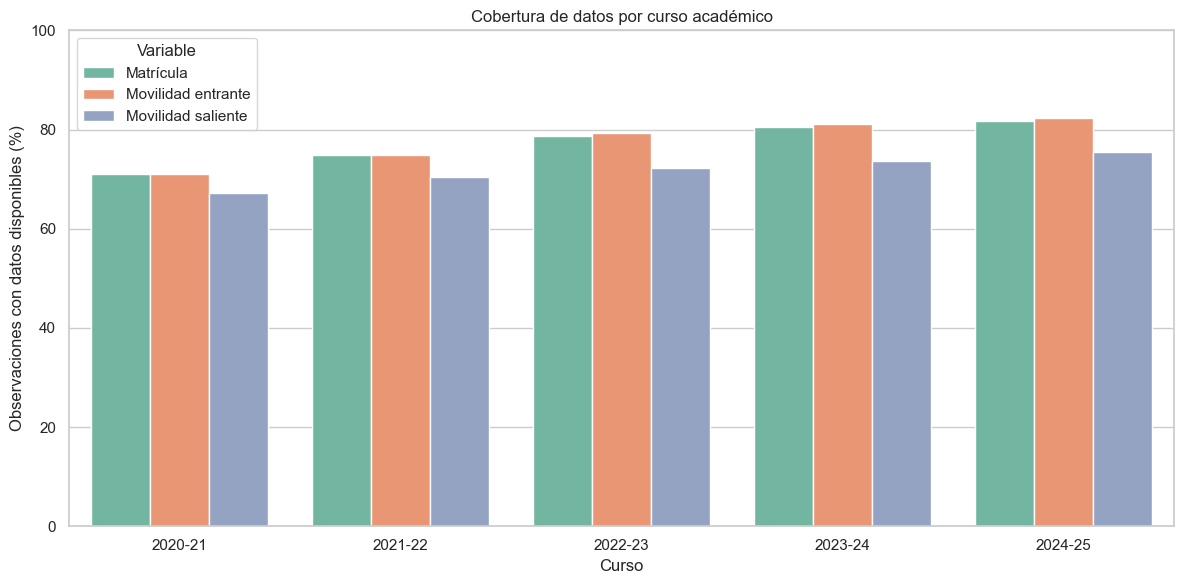

In [40]:

columnas_pct = {
    "CON_MATRICULA_PCT": "Matrícula",
    "CON_MOVILIDAD_ENTRANTE_PCT": "Movilidad entrante",
    "CON_MOVILIDAD_SALIENTE_PCT": "Movilidad saliente"
}

cobertura_larga = cobertura_curso.melt(
    id_vars="CURSO",
    value_vars=list(columnas_pct.keys()),
    var_name="VARIABLE",
    value_name="COBERTURA"
)

cobertura_larga["VARIABLE"] = (
    cobertura_larga["VARIABLE"].replace(columnas_pct)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=cobertura_larga,
    x="CURSO",
    y="COBERTURA",
    hue="VARIABLE"
)

plt.title("Cobertura de datos por curso académico")
plt.xlabel("Curso")
plt.ylabel("Observaciones con datos disponibles (%)")
plt.ylim(0, 100)
plt.legend(title="Variable")
plt.tight_layout()
plt.show()


In [42]:

df_cobertura["DATOS_COMPLETOS"] = (
    df_cobertura[variables].notna().all(axis=1)
)

cobertura_completa = (
    df_cobertura.groupby("CURSO")
    .agg(
        TOTAL=("COD_RUCT", "size"),
        COMPLETOS=("DATOS_COMPLETOS", "sum")
    )
    .reset_index()
)

cobertura_completa["COBERTURA_COMPLETA_PCT"] = (
    cobertura_completa["COMPLETOS"]
    / cobertura_completa["TOTAL"] * 100
)

display(cobertura_completa.round(2))


,CURSO,TOTAL,COMPLETOS,COBERTURA_COMPLETA_PCT
0,2020-21,159,107,67.30
1,2021-22,159,112,70.44
2,2022-23,159,115,72.33
3,2023-24,159,117,73.58
4,2024-25,159,120,75.47


In [43]:

output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)

df_final.to_csv(
    output_path / "upv_titulaciones_eda.csv",
    index=False,
    encoding="utf-8-sig"
)

cobertura_curso.to_csv(
    output_path / "cobertura_por_curso.csv",
    index=False,
    encoding="utf-8-sig"
)

cobertura_completa.to_csv(
    output_path / "cobertura_completa.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivos generados correctamente:")
for archivo in [
    "upv_titulaciones_eda.csv",
    "cobertura_por_curso.csv",
    "cobertura_completa.csv"
]:
    print(output_path / archivo)


Archivos generados correctamente:
..\data\processed\upv_titulaciones_eda.csv
..\data\processed\cobertura_por_curso.csv
..\data\processed\cobertura_completa.csv
